<img align="right" src="https://panoptes-uploads.zooniverse.org/project_avatar/86c23ca7-bbaa-4e84-8d8a-876819551431.png" type="image/png" height=100 width=100>
</img>
<h1 align="left">Train & Evaluate a YOLO Segmentation Model</h1>
<h4 align="left">Written by the KSO Team</h3>

This notebook trains (or fine-tunes) a YOLO instance segmentation model using [Ultralytics](https://docs.ultralytics.com/) directly.
It is designed to work with any compatible [YOLO dataset](https://docs.ultralytics.com/datasets/detect/) and supports:
                                                                                            
- **Training from scratch** using Ultralytics baseline models
- **Fine-tuning** from your own pretrained `.pt` weights

### Quick Start

1. Prepare your dataset (run `Biigle_to_YOLO_Seg.ipynb`, or bring your own YOLO-format segmentation dataset)
2. Update the **Phase 1: Configuration** cell with your paths and settings
3. Run all cells top to bottom
4. Use the test-set metrics (Phase 4) to evaluate your model

---

### Available Baseline Models

| Family | Sizes |
|--------|-------|
| **YOLOv8** | `yolov8n-seg.pt` &nbsp; `yolov8s-seg.pt` &nbsp; `yolov8m-seg.pt` &nbsp; `yolov8l-seg.pt` &nbsp; `yolov8x-seg.pt` |
| **YOLOv9** | `yolov9c-seg.pt` &nbsp; `yolov9e-seg.pt` |
| **YOLO11** | `yolo11n-seg.pt` &nbsp; `yolo11s-seg.pt` &nbsp; `yolo11m-seg.pt` &nbsp; `yolo11l-seg.pt` &nbsp; `yolo11x-seg.pt` |

> To fine-tune from your own model, set `baseline_weights` to the path of your `.pt` file.

### Model Size Tips

- **Small datasets (~100-250 frames):** nano or small - larger models will overfit
- **Medium datasets (~250-750 frames):** medium for a good balance
- **Large datasets (750+ frames):** large or xlarge for best accuracy

---
## Phase 1: Configuration

Edit these values to match your setup, then run the cell.

In [9]:
from pathlib import Path


# ── Paths ──
data_path = Path("/scratch/project_465002425/ferfersv/datasets/skane_merged_simplified_1.5")    # Dataset folder containing data.yaml
EXPERIMENT_ROOT = Path("/scratch/project_465002425/ferfersv/models")   # Where training runs are saved

# ── Experiment ──
exp_name = "LST_skane_M5_100E_11s_1.5_conf0.001"             # Name for this run (creates a subfolder)
baseline_weights = "yolo11s-seg.pt"                 # Ultralytics model name OR path to your .pt weights

# ── Training ──
epochs = 100         # Recommended: 50-150 depending on dataset size
batch_size = 8       # Reduce if you run out of GPU memory
img_size = 640       # Standard YOLO input size

# ── Evaluation ──
conf_thres = 0.001     # Confidence threshold for test evaluation

# ── Derived (no need to edit) ──
data_yaml = data_path / "data.yaml"

print(f"Dataset:   {data_path}")
print(f"Output:    {EXPERIMENT_ROOT / exp_name}")
print(f"Model:     {baseline_weights}")
print(f"Epochs:    {epochs}")

Dataset:   /scratch/project_465002425/ferfersv/datasets/skane_merged_simplified_1.5
Output:    /scratch/project_465002425/ferfersv/models/LST_skane_M5_100E_26s_1.5_conf0.001
Model:     yolo26s-seg.pt
Epochs:    100


---
## Phase 2: Verify Setup

Checks that paths exist and the environment is ready.

In [10]:
import os
import torch
from ultralytics import settings as ultra_settings

# Disable wandb to avoid login prompts / crashes
ultra_settings.update({"wandb": False})

# Compute safe worker count (half of available CPUs, minimum 1)
try:
    NUM_WORKERS = max(1, len(os.sched_getaffinity(os.getpid())) // 2)
except AttributeError:
    # macOS / systems without sched_getaffinity
    NUM_WORKERS = min(4, os.cpu_count() or 4)

# Check dataset
assert data_path.exists(), f"Dataset folder not found: {data_path}"
assert data_yaml.exists(), f"data.yaml not found: {data_yaml}"
print(f"Dataset:   {data_path}")

# Check for expected splits
for split in ("train", "valid"):
    split_dir = data_path / split
    assert split_dir.exists(), f"Required split missing: {split_dir}"
    n_images = len(list((split_dir / "images").glob("*"))) if (split_dir / "images").exists() else 0
    print(f"  {split + ':':10s} {n_images} images")

# Check test split (optional but needed for Phase 4)
test_dir = data_path / "test"
if test_dir.exists():
    n_test = len(list((test_dir / "images").glob("*"))) if (test_dir / "images").exists() else 0
    print(f"  {'test:':10s} {n_test} images")
else:
    print("test: NOT FOUND (Phase 4 will be skipped)")

# Check GPU
if torch.cuda.is_available():
    print(f"GPU:   {torch.cuda.get_device_name(0)}")
else:
    print("GPU:   None detected (training will be slow)")

# Create output directory
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Output dir:   {EXPERIMENT_ROOT}")
print(f"Workers:   {NUM_WORKERS}")
print()
print("Ready to train.")

Dataset:   /scratch/project_465002425/ferfersv/datasets/skane_merged_simplified_1.5
  train:     155 images
  valid:     44 images
  test:      22 images
GPU:   AMD Instinct MI250X
Output dir:   /scratch/project_465002425/ferfersv/models
Workers:   8

Ready to train.


---
## Phase 3: Train Model

Trains the YOLO model on your dataset. Duration depends on dataset size, model, and number of epochs.

Results are saved to `EXPERIMENT_ROOT/<exp_name>/`. If a directory with that name already exists, 
an error will be raised — change `exp_name` in Phase 1 to give each experiment a unique name.

In [11]:
# Check for existing experiment directory
exp_dir = EXPERIMENT_ROOT / exp_name
if exp_dir.exists() and any(exp_dir.iterdir()):
    raise FileExistsError(
        f"Experiment directory already exists and is not empty: {exp_dir}\n"
        f"Change exp_name in Phase 1 to start a new experiment, "
        f"or delete the directory to reuse this name."
    )

from ultralytics import YOLO

print(f"Training {baseline_weights} for {epochs} epochs...")
print(f"Base output: {EXPERIMENT_ROOT}")
print("=" * 50, "\n")

model = YOLO(baseline_weights)
results = model.train(
    data=str(data_yaml),
    epochs=epochs,
    batch=batch_size,
    imgsz=img_size,
    workers=NUM_WORKERS,
    project=str(EXPERIMENT_ROOT),
    name=exp_name,
    plots=True,
)

train_dir = Path(results.save_dir)
best_weights = train_dir / "weights" / "best.pt"

print(f"\n{'=' * 50}")
print(f"Training complete!")
print(f"  Run directory: {train_dir}")
print(f"  Best weights:  {best_weights}")

Training yolo26s-seg.pt for 100 epochs...
Base output: /scratch/project_465002425/ferfersv/models

New https://pypi.org/project/ultralytics/8.4.153 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.51 🚀 Python-3.12.3 torch-2.9.1+rocm6.4 CUDA:0 (AMD Instinct MI250X, 65520MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/scratch/project_465002425/ferfersv/datasets/skane_merged_simplified_1.5/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, ko

---
## Phase 4: Test Evaluation

Evaluates the best checkpoint on the held-out **test** split.
These are your publishable, unbiased metrics. Report them in your paper or thesis.

> If your dataset has no `test/` split, this phase will be skipped.

In [12]:
# Check that test split exists
test_dir = data_path / "test"
if not test_dir.exists():
    print("No test split found — skipping test evaluation.")
    print("To enable this, add a test/ folder to your dataset and re-run.")
else:
    # If you ran Phase 3 in this session, train_dir is already set.
    # To evaluate a previous run (skipping training), uncomment and edit:
    # train_dir = EXPERIMENT_ROOT / "your_run_folder"

    best_weights = train_dir / "weights" / "best.pt"
    assert best_weights.exists(), f"Weights not found: {best_weights}"

    print(f"Run dir: {train_dir}")
    print(f"Model:   {best_weights}")
    print(f"Evaluating on test set (conf={conf_thres})...\n")

    model = YOLO(str(best_weights))
    test_results = model.val(
        data=str(data_yaml),
        split="test",
        conf=conf_thres,
        workers=NUM_WORKERS,
        project=str(train_dir),
        name="test_eval",
        exist_ok=True,   
        plots=True,
    )

    print(f"\n{'=' * 50}")
    print("TEST SET RESULTS")
    print("=" * 50)
    print(f"  Box  mAP@50:    {test_results.box.map50:.3f}")
    print(f"  Box  mAP@50-95: {test_results.box.map:.3f}")
    print(f"  Mask mAP@50:    {test_results.seg.map50:.3f}")
    print(f"  Mask mAP@50-95: {test_results.seg.map:.3f}")
    print("=" * 50)
    print(f"\nResults saved to: {train_dir / 'test_eval'}")

Run dir: /pfs/lustrep2/scratch/project_465002425/ferfersv/models/LST_skane_M5_100E_26s_1.5_conf0.001
Model:   /pfs/lustrep2/scratch/project_465002425/ferfersv/models/LST_skane_M5_100E_26s_1.5_conf0.001/weights/best.pt
Evaluating on test set (conf=0.001)...

Ultralytics 8.4.51 🚀 Python-3.12.3 torch-2.9.1+rocm6.4 CUDA:0 (AMD Instinct MI250X, 65520MiB)
YOLO26s-seg summary (fused): 139 layers, 10,366,501 parameters, 0 gradients, 36.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5682.5±1153.5 MB/s, size: 2150.0 KB)
val: Scanning /pfs/lustrep2/scratch/project_465002425/ferfersv/datasets/skane_merged_simplified_1.5/test/labels.cache... 22 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.7s/it 9.4s<21.1s
                   all         22        101      0.654      0.421      0.431      0.276      0.678 

## Phase 5: Quick Visual Check

Run your trained model on a few samples to visually verify objects/instances. This cell picks random images from your test (or valid) split.  


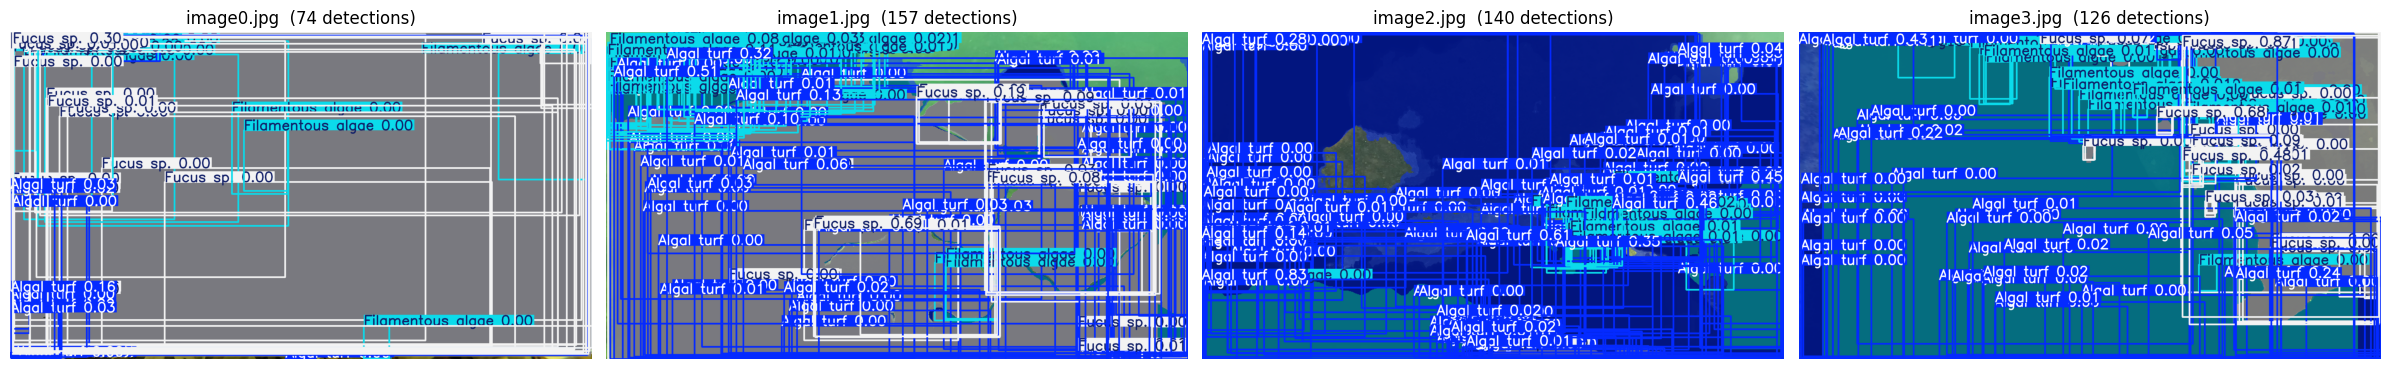

In [5]:
# =========================
# Predict on sample images
# =========================

%matplotlib inline
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

N_SAMPLES = 4  # Number of images to check

# Use test split if available, otherwise valid
check_split = data_path / "test" / "images"
if not check_split.exists():
    check_split = data_path / "valid" / "images"

images = sorted(check_split.glob("*"))
samples = random.sample(images, min(N_SAMPLES, len(images)))

model = YOLO(str(best_weights))
results = model.predict(samples, conf=conf_thres, verbose=False)

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 6))
if len(results) == 1:
    axes = [axes]
for ax, r in zip(axes, results):
    ax.imshow(r.plot()[:, :, ::-1])  # BGR -> RGB
    n_det = len(r.boxes)
    ax.set_title(f"{Path(r.path).name}  ({n_det} detection{'s' if n_det != 1 else ''})")
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## ✅ Done

### Output Structure

```
models/exp_name/
    weights/
        best.pt              # Best checkpoint — use this for inference
        last.pt              # Final checkpoint
    test_eval/               # Publishable results
        confusion_matrix.png
        PR_curve.png
        P_curve.png
        R_curve.png
        F1_curve.png
    results.png              # Training curves (for monitoring only)
```
### Rerun Behavior

Each experiment must have a unique `exp_name`. If you rerun training, change `exp_name` in Phase 1 
first. To evaluate a previous run after a kernel restart, set `train_dir` manually in Phase 4 and uncomment the line.

### Which Metrics to Report?

| Location | Purpose | Publishable? |
|----------|---------|:------------:|
| `<exp_name>/results.png` | Training progress (loss curves) | No |
| `<exp_name>/test_eval/` | Unbiased test-set evaluation | **Yes** |

---
### Using Your Model for Inference

```python
from ultralytics import YOLO

model = YOLO("path/to/your/models/<exp_name>/weights/best.pt")
results = model.predict("path/to/image.jpg")
```
### Next Steps

1. **Adjust hyperparameters** in Phase 1 and re-run training
2. **Compare experiments** by checking metrics across different `exp_name` runs
3. **Navigate to the next Notebook** `Model_Inference` 